# 18 - D22: which model is deployed, its calibration and its threshold

**In short:** notebook 17 trained ResNet-50 three times on `train_d22.csv` ("v3") and one run
of each other architecture. This notebook uses only the scores notebook 17 saved, so it
needs **no GPU**. It answers, in order, with rules fixed before any result was seen:

| # | Question | Rule |
|---|---|---|
| 1 | v3 or v2? | **D17 rule** (`src/adoption.py`), 3 seeds against 3: v3 is adopted only if its mean selection-set accuracy (crop given) is higher by more than the larger seed spread, the paired bootstrap range is above zero, and validation macro-F1 is not worse beyond the seed spread. |
| 2 | Does another architecture beat it? | **Rule B**: a challenger (one run) replaces ResNet only if its selection accuracy beats the ResNet's 3-seed mean by more than that ResNet's seed spread, the paired bootstrap range is above zero, validation macro-F1 is not worse beyond the seed spread, and it meets NFR iii (diagnosis within 10 s). |
| 3 | Single model or ensemble? | **D2** (notebook 13): the ensemble (ResNet + ConvNeXt-Tiny 1e-4 + EfficientNet-B0, as in notebook 13) wins only if its AURC is lower beyond the paired bootstrap range. |
| 4 | Calibration | **D6** (notebook 13): lowest out-of-sample log-loss among methods that never change the diagnosis; a tie keeps temperature scaling. |
| 5 | Threshold | **D7 clarified** (notebook 13b): the lowest threshold whose bootstrap lower bound of accuracy on answered photos is at least 90%; otherwise the pre-set cost-based fallback (a wrong answer costs 5 referrals). |

**Which ResNet seed is deployed:** the seed whose selection accuracy is closest to its
3-seed mean (a tie goes to the higher field-validation macro-F1): the typical model, not
the luckiest. For v2 this is seed 44, the seed already agreed on 22 Oct.

**What the backend can serve on 26 Oct:** one model of any architecture, with temperature
scaling. So, fixed before running: if the ensemble wins D2, that is reported as the better
design and the single model is deployed now; if D6 picks a method other than temperature
scaling, it is reported and temperature scaling (always computed) is deployed.

**Also reported, never used to choose:** per class and per source against v1 and v2 (where
each model gains and loses), confusion matrices, PlantDoc, and late fusion with the BERT text
classifier of notebook 11b (unchanged: it reads only the text, so it is reused as it is).

**Nothing earlier changes:** every earlier folder is only read; results go to
`d22_decision/`. The selection set has no maize northern leaf blight or potato early blight,
so the threshold is set without those two classes, as in notebook 13.

**How to run:** any runtime (CPU is enough). *Run all*. About 15-25 minutes, most of it the
calibration comparison and downloading the BERT text model. If notebook 17's second pass is
not finished, questions 2 and 3 use whatever runs exist and say which are missing.

In [1]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount("/content/drive")

REPO_URL = "https://github.com/BilliartMuthoni/confidence-calibrated-crop-diagnosis.git"
REPO_DIR = Path("/content/drive/MyDrive/Sproutly-app")

if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}

ML_DIR = REPO_DIR / "ml"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config

Mounted at /content/drive


In [2]:
# Keep the Drive copy of the repository in sync with GitHub.
!git -C {REPO_DIR} config core.fileMode false
!git -C {REPO_DIR} pull --ff-only
!git -C {REPO_DIR} status --short --branch

Already up to date.
Refresh index: 100% (384/384), done.
## main...origin/main
 M ml/notebooks/18_d22_decision.ipynb
?? ml/results/fusion_quick_test/


In [3]:
%pip install -q -r {ML_DIR}/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.3/378.3 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 407.8/407.8 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.4 MB/s eta 0:00:00


## Settings

In [4]:
import importlib
import json
import shutil

import numpy as np
import pandas as pd
import torch

from src import adoption, calibration as cal, fusion, metrics, text_encoders, training
for module in (adoption, cal, fusion, metrics, text_encoders, training):
    importlib.reload(module)

TARGET, COST_WRONG, FLOOR, BOOTSTRAP = 0.90, 5.0, 0.5, 1000
FOLDS, REPEATS = 5, 3
NFR_III_MS = 10_000
SEED = config.RANDOM_SEED

D17_DIR = config.MODELS_DIR / "d17_comparison"     # v1 and v2 scores (notebook 15): read only
D22_DIR = config.MODELS_DIR / "d22_comparison"     # notebook 17's scores: read only
OUT_DIR = config.MODELS_DIR / "d22_decision"
REPO_RESULTS = ML_DIR / "results" / "d22_decision"
LATE_HEAD = config.MODELS_DIR / "fusion_late_followup" / "late_head.pt"

V2 = [f"d17_resnet50_seed{s}" for s in (42, 43, 44)]
V3 = [f"d22_resnet50_seed{s}" for s in (42, 43, 44)]
V2_AGREED = "d17_resnet50_seed44"
CHALLENGERS = ["d22_efficientnet_b0", "d22_mobilenet_v3_large", "d22_densenet121", "d22_convnext_tiny",
               "d22_convnext_tiny_lr1e-04", "d22_swin_t"]
ENSEMBLE_PARTNERS = ["d22_convnext_tiny_lr1e-04", "d22_efficientnet_b0"]   # notebook 13's ensemble

# CPU time per photo does not depend on the training data (notebook 10, ml/results/comparison).
CPU_MS = pd.read_csv(ML_DIR / "results" / "comparison" / "comparison.csv", index_col=0)["cpu ms/image"].to_dict()


def architecture_of(run):
    return run.removeprefix("d22_").removeprefix("d17_").split("_seed")[0]


assert OUT_DIR.name not in {"calibration", "calibration_followup", "fusion_late_followup", "d17_comparison",
                            "d22_comparison", "compare_resnet50"}
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPO_RESULTS.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on", DEVICE)

Running on cpu


## The photos and every model's saved scores

Scores were saved by notebooks 15 (v1, v2) and 17 (v3 and the other architectures), all on
the same split files, in the same photo order.

In [5]:
EVAL_SETS = ["val", "test", "ood_test", "selection"]
splits = {name: pd.read_csv(config.SPLITS_DIR / f"{name}.csv") for name in EVAL_SETS}

CLASSES = list(config.PLANTVILLAGE_CLASSES)
INDEX = {name: i for i, name in enumerate(CLASSES)}
CLASS_CROPS = np.array([{"Corn_(maize)": "maize", "Tomato": "tomato", "Potato": "potato"}[c.split("___")[0]]
                        for c in CLASSES])
SHORT = {c: c.replace("Corn_(maize)___", "Maize ").replace("___", " ").replace("_", " ").strip() for c in CLASSES}
FIELD_SOURCES = ["fieldplant", "tanzania"]

PARTS = {}
for name in EVAL_SETS:
    labels = splits[name]["class"].map(INDEX)
    keep = labels.notna().to_numpy()
    lab = labels[keep].astype(int).to_numpy()
    PARTS[name] = {"rows": splits[name][keep].reset_index(drop=True), "keep": keep, "labels": lab,
                   "crops": CLASS_CROPS[lab]}


def load_scores(folder, run):
    files = {name: folder / f"{run}__{name}.npy" for name in EVAL_SETS}
    if not all(f.exists() for f in files.values()):
        return None
    scores = {name: np.load(f) for name, f in files.items()}
    for name in EVAL_SETS:
        assert len(scores[name]) == len(splits[name]), f"{run} {name}: {len(scores[name])} scores for {len(splits[name])} photos"
    return scores


SCORES = {"v1": load_scores(D17_DIR, "v1")}
SCORES.update({run: load_scores(D17_DIR, run) for run in V2})
SCORES.update({run: load_scores(D22_DIR, run) for run in V3})
missing = [run for run, s in SCORES.items() if s is None]
assert not missing, f"Scores missing for {missing}: run notebooks 15 and 17 (first pass) first"
AVAILABLE = [run for run in CHALLENGERS if load_scores(D22_DIR, run) is not None]
SCORES.update({run: load_scores(D22_DIR, run) for run in AVAILABLE})
NOT_TRAINED = [run for run in CHALLENGERS if run not in AVAILABLE]
print("Challengers with scores:", AVAILABLE or "none")
print("Not trained yet:", NOT_TRAINED or "none")

Challengers with scores: ['d22_efficientnet_b0', 'd22_mobilenet_v3_large', 'd22_densenet121', 'd22_convnext_tiny', 'd22_convnext_tiny_lr1e-04', 'd22_swin_t']
Not trained yet: none


In [6]:
def logits(run, name, mask=None):
    out = SCORES[run][name][PARTS[name]["keep"]]
    return out if mask is None else out[mask]


def app(probs, name, mask=None):
    # Confidence, prediction and correctness exactly as the app computes them (crop given).
    crops, labels = PARTS[name]["crops"], PARTS[name]["labels"]
    if mask is not None:
        crops, labels = crops[mask], labels[mask]
    conf, predicted = cal.crop_confidence(probs, CLASS_CROPS, crops)
    return conf, predicted, predicted == labels


def correct(run, name, mask=None):
    return app(metrics.softmax(logits(run, name, mask)), name, mask)[2]


FIELD = {name: PARTS[name]["rows"]["source"].isin(FIELD_SOURCES).to_numpy() for name in ["val", "test"]}


def macro_f1(run, name, mask=None):
    labels = PARTS[name]["labels"] if mask is None else PARTS[name]["labels"][mask]
    return metrics.summarise(logits(run, name, mask), labels, len(CLASSES))["macro_f1"]


def cpu_ms(run):
    return CPU_MS[architecture_of(run)]


overview = pd.DataFrame([{
    "run": run, "trained on": "train.csv" if run == "v1" else ("train_d17.csv" if run.startswith("d17_") else "train_d22.csv"),
    "val macro-F1": macro_f1(run, "val"), "val field macro-F1": macro_f1(run, "val", FIELD["val"]),
    "test macro-F1": macro_f1(run, "test"), "selection accuracy (crop given)": correct(run, "selection").mean(),
    "PlantDoc accuracy (crop given, reported only)": correct(run, "ood_test").mean(),
    "CPU ms per photo": cpu_ms(run if run != "v1" else "resnet50"),
} for run in SCORES]).set_index("run")
display(overview.round(4))

,trained on,val macro-F1,val field macro-F1,test macro-F1,selection accuracy (crop given),"PlantDoc accuracy (crop given, reported only)",CPU ms per photo
run,,,,,,,
v1,train.csv,0.9868,0.9948,0.9939,0.5745,0.3977,192.9966
d17_resnet50_seed42,train_d17.csv,0.9856,0.9695,0.9915,0.7228,0.4008,192.9966
d17_resnet50_seed43,train_d17.csv,0.9852,0.9923,0.9915,0.6148,0.4029,192.9966
d17_resnet50_seed44,train_d17.csv,0.9874,0.9820,0.9948,0.6577,0.4470,192.9966
d22_resnet50_seed42,train_d22.csv,0.9841,0.9938,0.9844,0.6548,0.5257,192.9966
d22_resnet50_seed43,train_d22.csv,0.9859,0.9689,0.9872,0.6689,0.5551,192.9966
d22_resnet50_seed44,train_d22.csv,0.9830,0.9621,0.9908,0.6726,0.5142,192.9966
d22_efficientnet_b0,train_d22.csv,0.9876,0.9812,0.9901,0.7145,0.5373,56.4848
d22_mobilenet_v3_large,train_d22.csv,0.9859,0.9791,0.9887,0.6880,0.5404,30.4142


## Question 1: v3 or v2? (D17 rule, 3 seeds against 3)

In [7]:
raw = adoption.decide([correct(r, "selection") for r in V3], [correct(r, "selection") for r in V2],
                      [macro_f1(r, "val") for r in V3], [macro_f1(r, "val") for r in V2], n=BOOTSTRAP, seed=SEED)
# adoption.py names the two sides "new" and "v1"; here they are v3 and v2.
Q1 = {k.replace("v1", "v2").replace("new", "v3"): v for k, v in raw.items() if k not in ("outcome", "reason", "adopt")}
better = Q1["difference_v3_minus_v2"] > Q1["margin"] and Q1["bootstrap_95_low"] > 0
Q1["v3_better"] = bool(better)
Q1["adopt_v3"] = bool(raw["adopt"])
Q1["outcome"] = "adopt v3" if raw["adopt"] else "keep v2"
Q1["reason"] = ("v3 better on the selection set beyond luck, validation not worse" if raw["adopt"] else
                "v3 better on the selection set, but validation worse beyond the seed spread" if better else
                f"v3 not better beyond luck: difference {Q1['difference_v3_minus_v2']:+.4f}, needed more than "
                f"{Q1['margin']:.4f} with the bootstrap range above zero ({Q1['bootstrap_95_low']:+.4f} to "
                f"{Q1['bootstrap_95_high']:+.4f})")
print(json.dumps(Q1, indent=1, default=float))
print("\nQUESTION 1:", Q1["outcome"].upper(), "-", Q1["reason"])

{
 "stage": 2,
 "seeds_v3": 3,
 "seeds_v2": 3,
 "selection_accuracy_v3_per_seed": [
  0.6548,
  0.6689,
  0.6726
 ],
 "selection_accuracy_v2_per_seed": [
  0.7228,
  0.6148,
  0.6577
 ],
 "difference_v3_minus_v2": 0.00034894879176472493,
 "seed_spread_v3": 0.01779638838000519,
 "seed_spread_v2": 0.10808688824914947,
 "bootstrap_95_low": -0.010034458693186777,
 "bootstrap_95_high": 0.010994067870539997,
 "validation_macro_f1_v3_mean": 0.9843603995074294,
 "validation_macro_f1_v2_mean": 0.9860756464470862,
 "validation_drop": 0.001715246939656856,
 "validation_drop_allowed": 0.0029227323997278454,
 "validation_ok": true,
 "margin": 0.10808688824914947,
 "v3_better": false,
 "adopt_v3": false,
 "outcome": "keep v2",
 "reason": "v3 not better beyond luck: difference +0.0003, needed more than 0.1081 with the bootstrap range above zero (-0.0100 to +0.0110)"
}

QUESTION 1: KEEP V2 - v3 not better beyond luck: difference +0.0003, needed more than 0.1081 with the bootstrap range above zero (-0.

In [8]:
def representative(runs):
    # The seed closest to its family's mean selection accuracy; a tie goes to the higher field-validation macro-F1.
    accuracy = {r: correct(r, "selection").mean() for r in runs}
    mean = np.mean(list(accuracy.values()))
    return min(runs, key=lambda r: (round(abs(accuracy[r] - mean), 6), -macro_f1(r, "val", FIELD["val"])))


assert representative(V2) == V2_AGREED, "the rule should pick v2's agreed seed 44"
FAMILY = V3 if Q1["adopt_v3"] else V2
FAMILY_NAME = "v3" if Q1["adopt_v3"] else "v2"
RESNET = representative(FAMILY)
print(f"ResNet-50 carried forward: {FAMILY_NAME}, run {RESNET}")

ResNet-50 carried forward: v2, run d17_resnet50_seed44


## Question 2: does another architecture beat it? (rule B)

Each challenger is one run on `train_d22.csv`, compared with the 3-seed family from question 1.

In [9]:
family_acc = np.array([correct(r, "selection").mean() for r in FAMILY])
family_val = np.array([macro_f1(r, "val") for r in FAMILY])
family_per_photo = np.mean([correct(r, "selection") for r in FAMILY], axis=0)
margin, val_allowed = float(np.ptp(family_acc)), float(np.ptp(family_val))

rows = []
for run in AVAILABLE:
    ok = correct(run, "selection").astype(float)
    low, high = cal.bootstrap(np.mean, ok - family_per_photo, n=BOOTSTRAP, seed=SEED)
    difference = ok.mean() - family_acc.mean()
    val_drop = family_val.mean() - macro_f1(run, "val")
    rows.append({"challenger": run, "selection accuracy": ok.mean(), f"{FAMILY_NAME} 3-seed mean": family_acc.mean(),
                 "difference": difference, "needed (seed spread)": margin, "bootstrap low": low, "bootstrap high": high,
                 "validation drop": val_drop, "validation drop allowed": val_allowed, "CPU ms per photo": cpu_ms(run),
                 "wins": bool(difference > margin and low > 0 and val_drop <= val_allowed and cpu_ms(run) <= NFR_III_MS)})
rule_b = pd.DataFrame(rows).set_index("challenger") if rows else pd.DataFrame()
if len(rule_b):
    display(rule_b.round(4))
winners = rule_b[rule_b["wins"]] if len(rule_b) else rule_b
SINGLE = winners["difference"].idxmax() if len(winners) else RESNET
Q2 = {"family": FAMILY_NAME, "family_runs": FAMILY, "margin": margin, "challengers_scored": AVAILABLE,
      "challengers_missing": NOT_TRAINED, "winners": list(winners.index), "single_model": SINGLE}
print("QUESTION 2:", f"{SINGLE} replaces ResNet-50" if SINGLE != RESNET else
      f"no challenger wins: {RESNET} stays" + (f" ({len(NOT_TRAINED)} challengers not trained)" if NOT_TRAINED else ""))

,selection accuracy,v2 3-seed mean,difference,needed (seed spread),bootstrap low,bootstrap high,validation drop,validation drop allowed,CPU ms per photo,wins
challenger,,,,,,,,,,
d22_efficientnet_b0,0.7145,0.6651,0.0494,0.1081,0.0346,0.0639,-0.0015,0.0022,56.4848,False
d22_mobilenet_v3_large,0.6880,0.6651,0.0229,0.1081,0.0099,0.0373,0.0002,0.0022,30.4142,False
d22_densenet121,0.6276,0.6651,-0.0375,0.1081,-0.0511,-0.0241,0.0005,0.0022,165.4490,False
d22_convnext_tiny,0.6854,0.6651,0.0203,0.1081,0.0071,0.0332,-0.0004,0.0022,211.7641,False
d22_convnext_tiny_lr1e-04,0.7242,0.6651,0.0591,0.1081,0.0440,0.0723,-0.0020,0.0022,197.6322,False
d22_swin_t,0.6205,0.6651,-0.0446,0.1081,-0.0576,-0.0318,-0.0019,0.0022,269.3249,False


QUESTION 2: no challenger wins: d17_resnet50_seed44 stays


## Question 3: single model or ensemble? (D2)

Both candidates are calibrated with their own D6 winner, out of fold (every photo scored by a
calibrator fitted without it), then the paired bootstrap of the AURC difference.

In [10]:
sel = PARTS["selection"]
CANDIDATES = {"single": logits(SINGLE, "selection")}
ENSEMBLE = [RESNET] + ENSEMBLE_PARTNERS
ensemble_ready = all(run in SCORES for run in ENSEMBLE)
if ensemble_ready:
    CANDIDATES["ensemble"] = np.log(np.mean([metrics.softmax(logits(r, "selection")) for r in ENSEMBLE], axis=0) + 1e-12)

D6, d6_tables = {}, []
for candidate, lg in CANDIDATES.items():
    table = cal.compare(lg, sel["labels"], folds=FOLDS, repeats=REPEATS, seed=SEED)
    method, reason = cal.choose_method(table)
    D6[candidate] = {"method": method, "reason": reason}
    d6_tables.append(table.assign(candidate=candidate))
d6 = pd.concat(d6_tables)
d6_summary = (d6.groupby(["candidate", "method"])
                .agg(nll=("nll", "mean"), nll_sd=("nll", "std"), ece=("ece", "mean"), brier=("brier", "mean"),
                     aurc=("aurc", "mean"), accuracy=("accuracy", "mean"), changed_predictions=("changed_predictions", "mean")))
d6_summary["can_win"] = [m in cal.KEEPS_PREDICTION for _, m in d6_summary.index]
display(d6_summary.round(4))

oof = {c: cal.out_of_fold(D6[c]["method"], lg, sel["labels"], FOLDS, SEED) for c, lg in CANDIDATES.items()}
oof_app = {c: app(p, "selection") for c, p in oof.items()}

if ensemble_ready:
    Q3 = cal.compare_models(oof_app["single"][0], oof_app["single"][2], oof_app["ensemble"][0], oof_app["ensemble"][2],
                            n=BOOTSTRAP, seed=SEED)
    Q3["ensemble"] = ENSEMBLE
    Q3["ensemble_cpu_ms"] = float(sum(cpu_ms(r) for r in ENSEMBLE))
    Q3["ensemble_meets_nfr_iii"] = Q3["ensemble_cpu_ms"] <= NFR_III_MS
    Q3["ensemble_better"] = bool(Q3["b_wins"] and Q3["ensemble_meets_nfr_iii"])
    Q3["outcome"] = ("ensemble refers better beyond the bootstrap range: reported as the better design; the backend serves "
                     "one model, so the single model is deployed now" if Q3["ensemble_better"]
                     else "ensemble not better beyond the bootstrap range: the single model stays")
else:
    Q3 = {"outcome": f"not run: {[r for r in ENSEMBLE if r not in SCORES]} not trained yet", "ensemble": ENSEMBLE}
print(json.dumps(Q3, indent=1, default=float))
DEPLOY = SINGLE

nll  nll_sd     ece   brier    aurc  accuracy  \
candidate method                                                          
ensemble  dirichlet    0.3111  0.0004  0.0205  0.1665  0.0218    0.8841   
          histogram    1.5783  0.0010  0.0179  0.5598  0.2142    0.6417   
          isotonic     1.5788  0.0007  0.0120  0.5593  0.2096    0.6417   
          none         1.8562  0.0000  0.1448  0.5804  0.2135    0.6417   
          temperature  1.2932  0.0002  0.0913  0.5507  0.2046    0.6417   
          vector       0.5815  0.0002  0.0481  0.2873  0.0606    0.8068   
single    dirichlet    0.3959  0.0012  0.0345  0.2087  0.0365    0.8595   
          histogram    2.0740  0.0004  0.0533  0.6576  0.3171    0.5258   
          isotonic     2.0797  0.0003  0.0558  0.6571  0.3177    0.5258   
          none         3.0439  0.0000  0.3546  0.7976  0.3191    0.5258   
          temperature  1.4825  0.0002  0.0372  0.6355  0.3270    0.5258   
          vector       0.8351  0.0006  0.0749  0.3914  0.1249    0.7430   

                       changed_predictions  can_win  
candidate method                                     
ensemble  dirichlet                 0.3530    False  
          histogram                 0.0000     True  
          isotonic                  0.0000     True  
          none                      0.0000     True  
          temperature               0.0000     True  
          vector                    0.3431    False  
single    dirichlet                 0.4427    False  
          histogram                 0.0000     True  
          isotonic                  0.0000     True  
          none                      0.0000     True  
          temperature               0.0000     True  
          vector                    0.3900    False

{
 "aurc_a": 0.19464112366796443,
 "aurc_b": 0.08610295827954424,
 "difference_b_minus_a": -0.10853816538842019,
 "difference_low": -0.12062879117185558,
 "difference_high": -0.0951833513533327,
 "b_wins": true,
 "ensemble": [
  "d17_resnet50_seed44",
  "d22_convnext_tiny_lr1e-04",
  "d22_efficientnet_b0"
 ],
 "ensemble_cpu_ms": 447.1136,
 "ensemble_meets_nfr_iii": true,
 "ensemble_better": true,
 "outcome": "ensemble refers better beyond the bootstrap range: reported as the better design; the backend serves one model, so the single model is deployed now"
}


## Questions 4 and 5: calibration and threshold for the deployed model

In [11]:
METHOD = D6["single"]["method"]
DEPLOY_METHOD = METHOD if METHOD in ("temperature", "none") else "temperature"
if DEPLOY_METHOD != METHOD:
    print(f"D6 chose {METHOD}; the backend applies temperature scaling, so temperature is deployed (fixed before running).")
    oof["single"] = cal.out_of_fold("temperature", CANDIDATES["single"], sel["labels"], FOLDS, SEED)
    oof_app["single"] = app(oof["single"], "selection")

conf_oof, _, correct_oof = oof_app["single"]
D7 = cal.choose_threshold_verified(conf_oof, correct_oof, TARGET, COST_WRONG, FLOOR, n=BOOTSTRAP, seed=SEED)
THRESHOLD = D7["threshold"]
D7["answered_at_threshold"] = cal.at_threshold(conf_oof, correct_oof, THRESHOLD)
print(json.dumps(D7, indent=1, default=float))

FINAL = cal.fit(DEPLOY_METHOD, CANDIDATES["single"], sel["labels"])
TEMPERATURE = FINAL.params.get("temperature", 1.0)
print(f"\nDeployed: {DEPLOY} | calibration {DEPLOY_METHOD} (T = {TEMPERATURE:.4f}) | threshold {THRESHOLD:.3f}")

{
 "threshold": 0.759,
 "target_reachable": true,
 "rule": "lowest threshold whose bootstrap lower bound of accuracy on answered photos is >= 90%",
 "original_rule_threshold": 0.7129719616600548,
 "best_lower_bound": 0.9187984496124031,
 "threshold_at_best_lower_bound": 0.8,
 "answered_at_threshold": {
  "threshold": 0.759,
  "coverage": 0.1599057838262235,
  "referred": 0.8400942161737766,
  "selective_accuracy": 0.9230769230769231,
  "wrong_and_answered": 0.0123004449097095
 }
}

Deployed: d17_resnet50_seed44 | calibration temperature (T = 3.8175) | threshold 0.759


## What the deployed model does on every set, before and after calibration

On the selection set the out-of-fold confidences are shown (no photo scored by a calibrator
that saw it). Test is in-domain, PlantDoc out-of-domain; neither was used to choose.

In [12]:
def scores_row(probs, name, mask=None):
    conf, _, ok = app(probs, name, mask)
    labels = PARTS[name]["labels"] if mask is None else PARTS[name]["labels"][mask]
    at = cal.at_threshold(conf, ok, THRESHOLD)
    return {"photos": len(labels), "accuracy (crop given)": ok.mean(), "mean confidence": conf.mean(),
            "ece": metrics.expected_calibration_error(conf, ok), "aurc": cal.aurc(conf, ok),
            "answered": at["coverage"], "accuracy of answered": at["selective_accuracy"],
            "wrong and answered": at["wrong_and_answered"]}


final_rows = []
for label, name, mask in [("selection (out of fold)", "selection", None), ("validation", "val", None),
                          ("test (in-domain)", "test", None), ("test: field photos", "test", FIELD["test"]),
                          ("PlantDoc (out-of-domain)", "ood_test", None)]:
    lg = logits(DEPLOY, name, mask)
    after = oof["single"] if name == "selection" else FINAL.probabilities(lg)
    final_rows.append({"set": label, "calibration": "none", **scores_row(metrics.softmax(lg), name, mask)})
    final_rows.append({"set": label, "calibration": DEPLOY_METHOD, **scores_row(after, name, mask)})
final = pd.DataFrame(final_rows).set_index(["set", "calibration"])
display(final.round(4))

photos  accuracy (crop given)  \
set                      calibration                                  
selection (out of fold)  none           3821                 0.6577   
                         temperature    3821                 0.6577   
validation               none           2385                 0.9912   
                         temperature    2385                 0.9912   
test (in-domain)         none           2441                 0.9963   
                         temperature    2441                 0.9963   
test: field photos       none            563                 0.9929   
                         temperature     563                 0.9929   
PlantDoc (out-of-domain) none            953                 0.4470   
                         temperature     953                 0.4470   

                                      mean confidence     ece    aurc  \
set                      calibration                                    
selection (out of fold)  none                  0.6628  0.2389  0.1863   
                         temperature           0.4309  0.2275  0.1946   
validation               none                  0.9915  0.0084  0.0005   
                         temperature           0.8675  0.1237  0.0006   
test (in-domain)         none                  0.9946  0.0035  0.0005   
                         temperature           0.8691  0.1272  0.0008   
test: field photos       none                  0.9903  0.0095  0.0054   
                         temperature           0.7906  0.2023  0.0075   
PlantDoc (out-of-domain) none                  0.6474  0.4138  0.5148   
                         temperature           0.4329  0.1553  0.4926   

                                      answered  accuracy of answered  \
set                      calibration                                   
selection (out of fold)  none           0.5970                0.7790   
                         temperature    0.1599                0.9231   
validation               none           0.9878                0.9932   
                         temperature    0.8386                0.9985   
test (in-domain)         none           0.9939                0.9967   
                         temperature    0.8382                0.9990   
test: field photos       none           0.9911                0.9928   
                         temperature    0.6412                0.9945   
PlantDoc (out-of-domain) none           0.5582                0.4624   
                         temperature    0.1291                0.5691   

                                      wrong and answered  
set                      calibration                      
selection (out of fold)  none                     0.1319  
                         temperature              0.0123  
validation               none                     0.0067  
                         temperature              0.0013  
test (in-domain)         none                     0.0033  
                         temperature              0.0008  
test: field photos       none                     0.0071  
                         temperature              0.0036  
PlantDoc (out-of-domain) none                     0.3001  
                         temperature              0.0556

## Where each model gains and loses (reported only)

Accuracy with the crop given, per class and source. v2 and v3 are the means of their three
seeds; v1 is the model the backend serves today. "Change" is the deployed model minus v1.

In [13]:
def per_group(name, by):
    rows = PARTS[name]["rows"].assign(cls=lambda d: d["class"].map(SHORT))
    out = []
    for key, group in rows.groupby(by):
        mask = np.zeros(len(rows), bool)
        mask[group.index.to_numpy()] = True
        entry = dict(zip(by, key if isinstance(key, tuple) else (key,)))
        entry["photos"] = int(mask.sum())
        entry["v1"] = correct("v1", name, mask).mean()
        entry["v2 (mean of 3)"] = np.mean([correct(r, name, mask).mean() for r in V2])
        entry["v3 (mean of 3)"] = np.mean([correct(r, name, mask).mean() for r in V3])
        entry[f"deployed ({DEPLOY})"] = correct(DEPLOY, name, mask).mean()
        entry["change vs v1"] = entry[f"deployed ({DEPLOY})"] - entry["v1"]
        out.append(entry)
    return pd.DataFrame(out).set_index(by)


selection_by_source_class = per_group("selection", ["source", "cls"])
test_by_class = per_group("test", ["cls"])
plantdoc_by_class = per_group("ood_test", ["cls"])
for title, table in [("Selection set by source and class", selection_by_source_class),
                     ("Test set by class", test_by_class), ("PlantDoc by class (reported only)", plantdoc_by_class)]:
    print(title)
    display(table.round(3))

Selection set by source and class


photos     v1  \
source          cls                                                        
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot     554  0.733   
                Maize healthy                                 359  0.994   
maize_natore    Maize Cercospora leaf spot Gray leaf spot     826  0.460   
                Maize Common rust                             126  0.444   
                Maize healthy                                 602  0.869   
potato_holeta   Potato Late blight                             67  0.985   
                Potato healthy                                344  0.817   
tomato_bd       Tomato Bacterial spot                          97  0.000   
                Tomato Early blight                           447  0.098   
                Tomato Late blight                             92  0.848   
                Tomato healthy                                307  0.013   

                                                           v2 (mean of 3)  \
source          cls                                                         
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot           0.682   
                Maize healthy                                       0.994   
maize_natore    Maize Cercospora leaf spot Gray leaf spot           0.597   
                Maize Common rust                                   0.119   
                Maize healthy                                       0.911   
potato_holeta   Potato Late blight                                  0.995   
                Potato healthy                                      0.991   
tomato_bd       Tomato Bacterial spot                               0.158   
                Tomato Early blight                                 0.383   
                Tomato Late blight                                  0.692   
                Tomato healthy                                      0.301   

                                                           v3 (mean of 3)  \
source          cls                                                         
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot           0.647   
                Maize healthy                                       0.993   
maize_natore    Maize Cercospora leaf spot Gray leaf spot           0.586   
                Maize Common rust                                   0.844   
                Maize healthy                                       0.888   
potato_holeta   Potato Late blight                                  0.995   
                Potato healthy                                      0.995   
tomato_bd       Tomato Bacterial spot                               0.031   
                Tomato Early blight                                 0.429   
                Tomato Late blight                                  0.525   
                Tomato healthy                                      0.166   

                                                           deployed (d17_resnet50_seed44)  \
source          cls                                                                         
maize_jhenaidah Maize Cercospora leaf spot Gray leaf spot                           0.688   
                Maize healthy                                                       0.994   
maize_natore    Maize Cercospora leaf spot Gray leaf spot                           0.508   
                Maize Common rust                                                   0.151   
                Maize healthy                                                       0.927   
potato_holeta   Potato Late blight                                                  1.000   
                Potato healthy                                                      0.988   
tomato_bd       Tomato Bacterial spot                                               0.000   
                Tomato Early blight                                                 0.568   
                Tomato Late blight         

Test set by class


,photos,v1,v2 (mean of 3),v3 (mean of 3),deployed (d17_resnet50_seed44),change vs v1
cls,,,,,,
Maize Cercospora leaf spot Gray leaf spot,93,0.978,0.971,0.903,0.957,-0.022
Maize Common rust,176,1.000,1.000,1.000,1.000,0.000
Maize Northern Leaf Blight,150,0.993,0.993,0.996,1.000,0.007
Maize healthy,201,1.000,1.000,1.000,1.000,0.000
Potato Early blight,279,0.996,1.000,0.996,1.000,0.004
Potato Late blight,297,0.993,0.993,0.994,0.997,0.003
Potato healthy,169,1.000,1.000,1.000,1.000,0.000
Tomato Bacterial spot,304,1.000,1.000,1.000,1.000,0.000
Tomato Early blight,160,0.981,0.985,0.981,0.994,0.013


PlantDoc by class (reported only)


,photos,v1,v2 (mean of 3),v3 (mean of 3),deployed (d17_resnet50_seed44),change vs v1
cls,,,,,,
Maize Cercospora leaf spot Gray leaf spot,65,0.846,0.923,0.779,0.877,0.031
Maize Common rust,116,0.224,0.305,0.626,0.362,0.138
Maize Northern Leaf Blight,189,0.190,0.104,0.437,0.148,-0.042
Potato Early blight,112,0.500,0.324,0.381,0.375,-0.125
Potato Late blight,100,0.700,0.773,0.763,0.730,0.030
Tomato Bacterial spot,109,0.028,0.073,0.116,0.092,0.064
Tomato Early blight,88,0.216,0.420,0.561,0.523,0.307
Tomato Late blight,111,0.973,0.799,0.739,0.829,-0.144
Tomato healthy,63,0.095,0.556,0.598,0.571,0.476


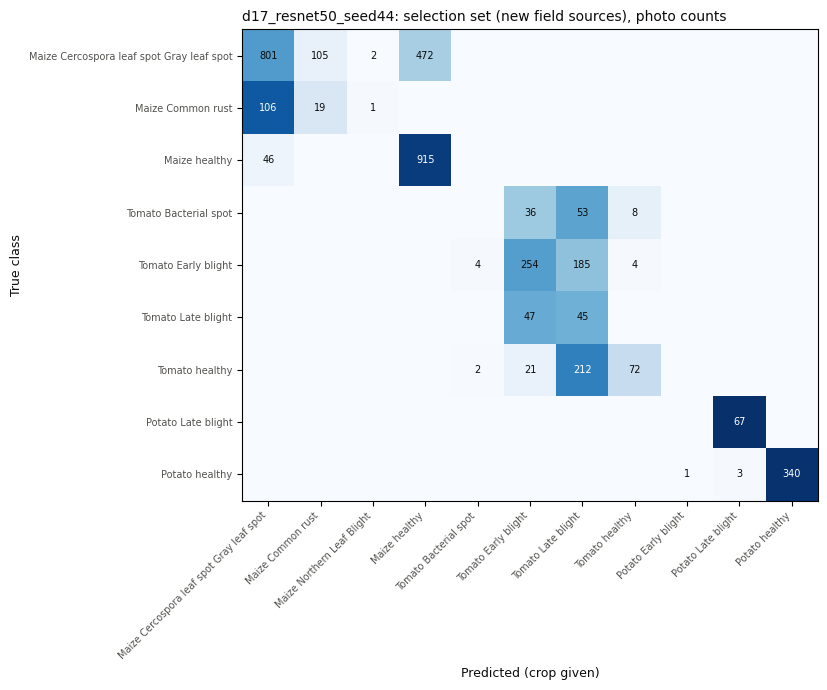

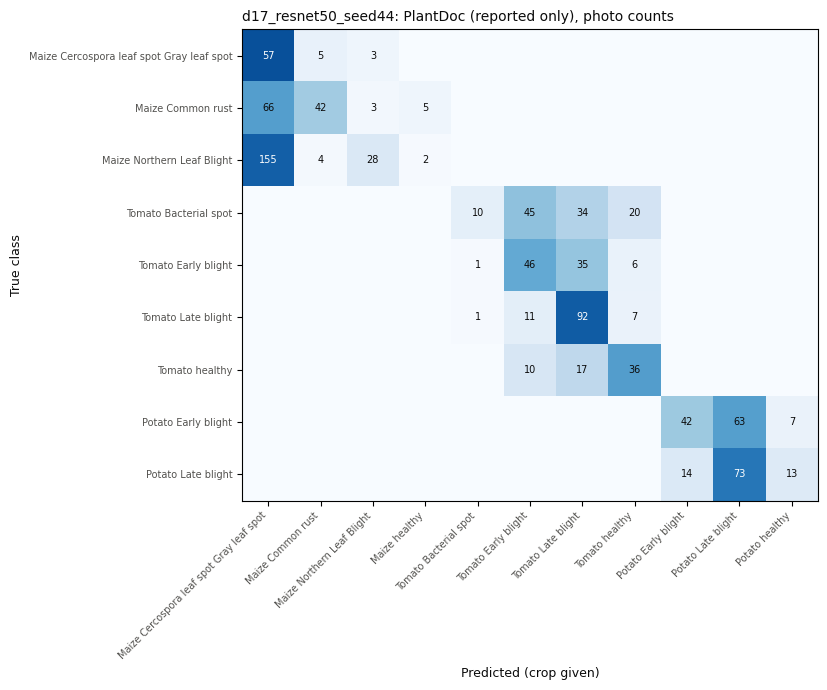

In [14]:
import matplotlib.pyplot as plt

INK, MUTED = "#0b0b0b", "#52514e"


def confusion(name, title, file):
    _, predicted, _ = app(metrics.softmax(logits(DEPLOY, name)), name)
    labels = PARTS[name]["labels"]
    present = sorted(set(labels) | set(predicted))
    matrix = pd.crosstab(pd.Series([SHORT[CLASSES[i]] for i in labels], name="true class"),
                         pd.Series([SHORT[CLASSES[i]] for i in predicted], name="predicted (crop given)"))
    names = [SHORT[CLASSES[i]] for i in present]
    matrix = matrix.reindex(index=[n for n in names if n in matrix.index], columns=names, fill_value=0)
    shares = matrix.div(matrix.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(shares.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    for i in range(shares.shape[0]):
        for j in range(shares.shape[1]):
            if matrix.iat[i, j]:
                ax.text(j, i, matrix.iat[i, j], ha="center", va="center", fontsize=7,
                        color="white" if shares.iat[i, j] > 0.6 else INK)
    ax.set_xticks(range(len(shares.columns)), shares.columns, rotation=45, ha="right", fontsize=7, color=MUTED)
    ax.set_yticks(range(len(shares.index)), shares.index, fontsize=7, color=MUTED)
    ax.set_xlabel("Predicted (crop given)", color=INK, fontsize=9)
    ax.set_ylabel("True class", color=INK, fontsize=9)
    ax.set_title(title, color=INK, fontsize=10, loc="left")
    plt.tight_layout()
    plt.savefig(OUT_DIR / file, dpi=150)
    plt.show()
    matrix.to_csv(OUT_DIR / file.replace(".png", ".csv"))


confusion("selection", f"{DEPLOY}: selection set (new field sources), photo counts", "confusion_selection.png")
confusion("ood_test", f"{DEPLOY}: PlantDoc (reported only), photo counts", "confusion_plantdoc.png")

## Late fusion with the BERT text classifier (notebook 11b), on the deployed model

The text classifier reads only the farmer's sentence, so it is loaded unchanged and
combined with the new image scores as a product of experts. Each test photo of a disease
gets one held-out test sentence of its class; healthy photos get none.

In [ ]:
descriptions = pd.read_csv(ML_DIR / "data" / "symptoms" / "descriptions.csv", encoding="utf-8-sig")
descriptions = descriptions[descriptions["keep"] == "y"].reset_index(drop=True)
texts = descriptions["text"].tolist()
train_texts = descriptions.loc[descriptions["split"] == "train", "text"].tolist()
vectors = text_encoders.encode("bert_base", texts, train_texts, DEVICE)
test_bank = fusion.TextBank.build(descriptions, vectors, CLASSES, "test")

head = fusion.TextClassifier(vectors.shape[1], int((~fusion.healthy_mask(CLASSES)).sum()))
head.load_state_dict(torch.load(LATE_HEAD, map_location="cpu"))
head.to(DEVICE).eval()


def features(name, mask=None):
    lg = logits(DEPLOY, name, mask)
    labels = PARTS[name]["labels"] if mask is None else PARTS[name]["labels"][mask]
    return fusion.Features(np.zeros((len(labels), 1), np.float32), lg, labels)


fusion_rows = []
for label, name, mask in [("test", "test", None), ("test: field", "test", FIELD["test"]), ("PlantDoc", "ood_test", None)]:
    part = features(name, mask)
    fused = fusion.predict("late", head, part, *test_bank.fixed(part.labels), CLASSES, DEVICE)
    fusion_rows.append({"set": label, "condition": f"{DEPLOY} alone", **metrics.summarise(part.logits, part.labels, len(CLASSES))})
    fusion_rows.append({"set": label, "condition": "late fusion, with test text", **metrics.summarise(fused, part.labels, len(CLASSES))})
fusion_table = pd.DataFrame(fusion_rows).set_index(["set", "condition"])
display(fusion_table.round(4))
FUSION_BIAS = fusion.bias_tests("late", head, features("test", FIELD["test"]), test_bank, CLASSES, DEVICE)
display(pd.Series(FUSION_BIAS).round(3))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

## Save the decision and the backend settings

In [ ]:
family = "v3" if DEPLOY in V3 else "v2" if DEPLOY in V2 else "d22"
seed = DEPLOY.split("_seed")[1] if "_seed" in DEPLOY else "42"
version = f"{family}-{architecture_of(DEPLOY)}-seed{seed}"
calibrator = {"model_run": DEPLOY, "model_version": version, "architecture": architecture_of(DEPLOY),
              "method": DEPLOY_METHOD, "temperature": TEMPERATURE, "threshold": THRESHOLD, "rule": D7["rule"],
              "fitted_on": f"selection set ({len(sel['labels'])} photos)",
              "confidence": "best class of the farmer's crop, 11-class probability, not rescaled"}
decision = {"question_1_v3_or_v2": Q1, "question_2_rule_b": Q2, "question_3_ensemble": Q3, "D6": D6,
            "deployed_method": DEPLOY_METHOD, "D7": D7, "fusion_bias": FUSION_BIAS, "deployed": calibrator,
            "rules": "fixed before notebook 18 ran: D17 rule (src/adoption.py), rule B, D2, D6, D7 clarified (13b)"}
training.save_json(calibrator, OUT_DIR / "calibrator_final.json")
training.save_json(decision, OUT_DIR / "decision.json")
overview.to_csv(OUT_DIR / "overview.csv")
if len(rule_b):
    rule_b.to_csv(OUT_DIR / "rule_b.csv")
d6_summary.to_csv(OUT_DIR / "d6_methods.csv")
final.to_csv(OUT_DIR / "final_metrics.csv")
selection_by_source_class.to_csv(OUT_DIR / "selection_by_source_class.csv")
test_by_class.to_csv(OUT_DIR / "test_by_class.csv")
plantdoc_by_class.to_csv(OUT_DIR / "plantdoc_by_class.csv")
fusion_table.to_csv(OUT_DIR / "late_fusion.csv")

print("Backend settings for this model (put them in the backend's environment, not in Git):")
print(f"  ML_MODEL_PATH        = models/{DEPLOY}/model.pt   (copy model.pt from Drive: CropDiseaseDiagnosis/models/{DEPLOY}/)")
print(f"  TEMPERATURE          = {TEMPERATURE:.4f}")
print(f"  CONFIDENCE_THRESHOLD = {THRESHOLD:.3f}")
print(f"  model version        = {version}")

## Copy the results into the repository, sync Drive, save to GitHub

Save the notebook first (Ctrl+S).

In [ ]:
for file in OUT_DIR.glob("*"):
    if file.suffix in {".csv", ".json", ".png"}:
        shutil.copy(file, REPO_RESULTS / file.name)
print(sorted(p.name for p in REPO_RESULTS.iterdir()))
drive.flush_and_unmount()
drive.mount("/content/drive")

In [ ]:
from google.colab import userdata

from src import github_sync

PART = "all" if not NOT_TRAINED else "partial"
shutil.copy(ML_DIR / "notebooks" / "18_d22_decision.ipynb", REPO_RESULTS / f"notebook_{PART}.ipynb")
print(github_sync.push(
    REPO_DIR,
    branch=f"colab/d22-decision-{PART}",
    message=f"D22: v3 or v2, architecture and ensemble checks, calibration and threshold ({PART})",
    token=userdata.get("GITHUB_TOKEN"),
    name="BilliartMuthoni",
    email=userdata.get("GIT_EMAIL"),
    paths=[str(REPO_RESULTS.relative_to(REPO_DIR))],
))